# 📱 Mobile-Wallet Fraud Detection (PaySim)
**NextGen Institute · Machine Learning · Final Project — Idea #06 (FinTech · Payments · Imbalanced Classification)**

**Team / Author:** _abdelrahman khalid_  ·  **Dataset:** [PaySim Mobile Money Simulation (Kaggle)](https://www.kaggle.com/datasets/ealaxi/paysim1) (~6.3M transactions)

### How to run
1. Download the CSV from Kaggle (`PS_20174392719_1491204439457_log.csv`) and put it next to this notebook — **or** just run the notebook: if the file is missing it tries `kagglehub` (needs Kaggle access).
2. `Kernel → Restart & Run All`. Everything below is computed by this code; no number is typed by hand.
3. The last cells create the deployable files: `fraud_pipeline.joblib`, `app.py`, `requirements.txt`, `README.md`.

> Tip: if your laptop is slow, lower `SAMPLE_N` and `N_ITER` in the config cell.

## 1 · Problem framing

**Who has the problem?** Mobile-money providers (e.g. Vodafone Cash, InstaPay) and their customers. Fraud grows as fast as the service.

**What decision does the model support?** For every `TRANSFER` / `CASH_OUT` transaction, the fraud-ops team must decide: *let it pass* or *block / hold for review*.

**Target variable:** `isFraud` (1 = fraudulent, 0 = legitimate).

**Costs are asymmetric**
- *Missed fraud (false negative)* → the customer loses the money and the provider usually refunds it → cost ≈ the **transaction amount**.
- *False alarm (false positive)* → an honest user is blocked / needs a manual review → cost ≈ a **fixed friction cost** per case (an assumption, set below and easy to change).

**Metric that matters:** with ~0.1% fraud, **accuracy is useless** (predicting "never fraud" scores ~99.9%). We select models by **PR-AUC (Average Precision)**, which focuses on the rare class, and we report precision / recall / F1 / ROC-AUC. The final operating **threshold** is chosen by minimizing the **total business cost** (missed fraud amount + false-alarm cost).

In [1]:
%pip install kagglehub

     ---------------------------------------- 0.0/40.4 kB ? eta -:--:--
     ---------- ----------------------------- 10.2/40.4 kB ? eta -:--:--
     ------------------- ------------------ 20.5/40.4 kB 330.3 kB/s eta 0:00:01
     ------------------- ------------------ 20.5/40.4 kB 330.3 kB/s eta 0:00:01
     ------------------- ------------------ 20.5/40.4 kB 330.3 kB/s eta 0:00:01
     ------------------- ------------------ 20.5/40.4 kB 330.3 kB/s eta 0:00:01
     ------------------- ------------------ 20.5/40.4 kB 330.3 kB/s eta 0:00:01
     ------------------- ------------------ 20.5/40.4 kB 330.3 kB/s eta 0:00:01
     ------------------- ------------------ 20.5/40.4 kB 330.3 kB/s eta 0:00:01
     --------------------------------------- 40.4/40.4 kB 87.6 kB/s eta 0:00:00
   ---------------------------------------- 0.0/73.3 kB ? eta -:--:--
   ---------------------------------------- 0.0/73.3 kB ? eta -:--:--
   ----- ---------------------------------- 10.2/73.3 kB ? eta -:--:--
   -

**Install once if needed:** Run `%pip install numpy pandas matplotlib seaborn scikit-learn scipy joblib kagglehub streamlit` in a separate cell, restart the kernel, then Restart & Run All. Downloading the 6.3M-row dataset needs internet and disk space. Training may take a while.


In [2]:
import os, glob, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50, "display.float_format", "{:,.4f}".format)

RANDOM_STATE = 42
SAMPLE_N  = 400_000   # rows used for modeling (stratified sample of TRANSFER/CASH_OUT). Lower it if slow.
N_ITER    = 6         # random-search iterations per model
CV_FOLDS  = 3
FP_COST   = 10.0      # ASSUMPTION: cost (same currency units as `amount`) of blocking an honest transaction.
                      # Change it to match your business assumption and re-run.
np.random.seed(RANDOM_STATE)

## 3 · Data understanding

In [4]:
def find_csv():
    candidates = ["PS_20174392719_1491204439457_log.csv", "paysim.csv"]
    candidates += glob.glob("PS_*.csv") + glob.glob("data/PS_*.csv")
    return next((p for p in candidates if os.path.isfile(p)), None)

path = find_csv()
if path is None:
    try:
        import kagglehub
        folder = kagglehub.dataset_download("ealaxi/paysim1")
        files = glob.glob(os.path.join(folder, "*.csv"))
        if not files:
            raise FileNotFoundError("Downloaded folder contains no CSV")
        path = files[0]
    except Exception as e:
        raise FileNotFoundError("Install kagglehub with %pip install kagglehub, or place the PaySim CSV beside this notebook.") from e

df = pd.read_csv(path)
print("Loaded:", path)
print("Shape:", df.shape, "| memory: %.0f MB" % (df.memory_usage(deep=True).sum()/1e6))
df.head()


Resuming download from 9437184 bytes (176948377 bytes left)...
Resuming download to C:\Users\Bedo\.cache\kagglehub\datasets\ealaxi\paysim1\2.archive (9437184/186385561) bytes left.


100%|███████████████████████████████████████████████████████████████████████████████| 178M/178M [01:30<00:00, 1.94MB/s]

Extracting files...


Loaded: C:\Users\Bedo\.cache\kagglehub\datasets\ealaxi\paysim1\versions\2\PS_20174392719_1491204439457_log.csv
Shape: (6362620, 11) | memory: 1523 MB


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.6400",C1231006815,"170,136.0000","160,296.3600",M1979787155,0.0000,0.0000,0,0
1,1,PAYMENT,"1,864.2800",C1666544295,"21,249.0000","19,384.7200",M2044282225,0.0000,0.0000,0,0
2,1,TRANSFER,181.0000,C1305486145,181.0000,0.0000,C553264065,0.0000,0.0000,1,0
3,1,CASH_OUT,181.0000,C840083671,181.0000,0.0000,C38997010,"21,182.0000",0.0000,1,0
4,1,PAYMENT,"11,668.1400",C2048537720,"41,554.0000","29,885.8600",M1230701703,0.0000,0.0000,0,0


### Column dictionary
| Column | Meaning | Type |
|---|---|---|
| `step` | Time unit: 1 step = 1 hour (744 steps ≈ 30 days) | int |
| `type` | CASH-IN, CASH-OUT, DEBIT, PAYMENT, TRANSFER | categorical |
| `amount` | Transaction amount (local currency) | float |
| `nameOrig` | Customer who started the transaction | id (dropped) |
| `oldbalanceOrg` / `newbalanceOrig` | Sender balance before / after | float |
| `nameDest` | Recipient of the transaction | id (dropped) |
| `oldbalanceDest` / `newbalanceDest` | Recipient balance before / after (unknown for merchants) | float |
| `isFraud` | **Target** – transaction made by a fraudulent agent | 0/1 |
| `isFlaggedFraud` | The simulator's own naive rule (amount > 200,000 transfers) | 0/1 |

In [5]:
print(df.dtypes, "\n")
print("Missing values per column:\n", df.isna().sum(), "\n")
print("Duplicated rows:", df.duplicated().sum())
display(df.describe().T)

vc = df["isFraud"].value_counts()
print(f"\nClass balance -> legit: {vc[0]:,} | fraud: {vc[1]:,} | fraud rate: {df['isFraud'].mean()*100:.4f}%")
print("Naive 'never fraud' accuracy would be:", f"{(1-df['isFraud'].mean())*100:.3f}%")

step                int64
type               object
amount            float64
nameOrig           object
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest           object
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object 

Missing values per column:
 step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64 

Duplicated rows: 0


,count,mean,std,min,25%,50%,75%,max
step,"6,362,620.0000",243.3972,142.3320,1.0000,156.0000,239.0000,335.0000,743.0000
amount,"6,362,620.0000","179,861.9035","603,858.2315",0.0000,"13,389.5700","74,871.9400","208,721.4775","92,445,516.6400"
oldbalanceOrg,"6,362,620.0000","833,883.1041","2,888,242.6730",0.0000,0.0000,"14,208.0000","107,315.1750","59,585,040.3700"
newbalanceOrig,"6,362,620.0000","855,113.6686","2,924,048.5030",0.0000,0.0000,0.0000,"144,258.4100","49,585,040.3700"
oldbalanceDest,"6,362,620.0000","1,100,701.6665","3,399,180.1130",0.0000,0.0000,"132,705.6650","943,036.7075","356,015,889.3500"
newbalanceDest,"6,362,620.0000","1,224,996.3982","3,674,128.9421",0.0000,0.0000,"214,661.4400","1,111,909.2500","356,179,278.9200"
isFraud,"6,362,620.0000",0.0013,0.0359,0.0000,0.0000,0.0000,0.0000,1.0000
isFlaggedFraud,"6,362,620.0000",0.0000,0.0016,0.0000,0.0000,0.0000,0.0000,1.0000



Class balance -> legit: 6,354,407 | fraud: 8,213 | fraud rate: 0.1291%
Naive 'never fraud' accuracy would be: 99.871%


In [6]:
print("Fraud by transaction type:")
display(df.groupby("type")["isFraud"].agg(n="size", frauds="sum", fraud_rate="mean"))

print("The simulator's own rule (isFlaggedFraud) vs. truth:")
display(pd.crosstab(df["isFlaggedFraud"], df["isFraud"], margins=True))

Fraud by transaction type:


,n,frauds,fraud_rate
type,,,
CASH_IN,1399284,0,0.0000
CASH_OUT,2237500,4116,0.0018
DEBIT,41432,0,0.0000
PAYMENT,2151495,0,0.0000
TRANSFER,532909,4097,0.0077


The simulator's own rule (isFlaggedFraud) vs. truth:


isFraud,0,1,All
isFlaggedFraud,,,
0,6354407,8197,6362604
1,0,16,16
All,6354407,8213,6362620


## 4 · Exploratory Data Analysis

In [7]:
# Fraud happens only in some types -> check, then focus on those.
fraud_types = sorted(df.loc[df.isFraud == 1, "type"].unique())
print("Types that contain fraud:", fraud_types)

# Work on the relevant scope (fraud exists only there). Everything is exploratory: nothing is fitted here.
dff = df[df["type"].isin(fraud_types)].reset_index(drop=True)
print(f"Scope: {len(dff):,} rows ({len(dff)/len(df):.1%} of data) | fraud rate inside scope: {dff.isFraud.mean()*100:.3f}%")

# Plot sample for speed: keep all frauds + a random slice of legit rows.
eda = pd.concat([dff[dff.isFraud == 1], dff[dff.isFraud == 0].sample(min(150_000, (dff.isFraud==0).sum()), random_state=RANDOM_STATE)])

Types that contain fraud: ['CASH_OUT', 'TRANSFER']
Scope: 2,770,409 rows (43.5% of data) | fraud rate inside scope: 0.296%


### 4.1 Univariate

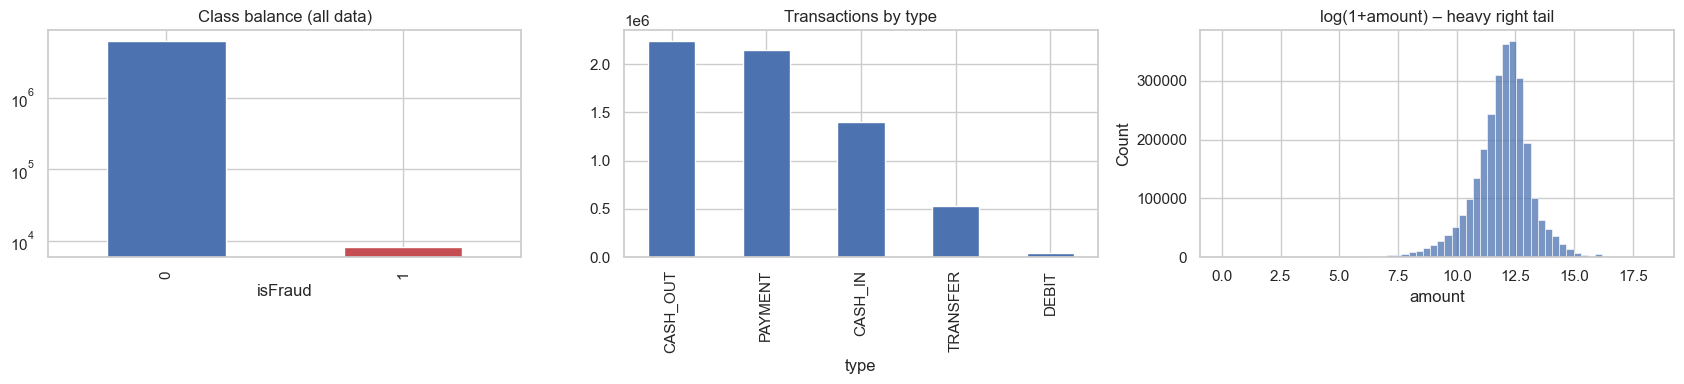

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
df["isFraud"].value_counts().plot.bar(ax=ax[0], color=["#4c72b0", "#c44e52"]); ax[0].set_title("Class balance (all data)"); ax[0].set_yscale("log")
df["type"].value_counts().plot.bar(ax=ax[1], color="#4c72b0"); ax[1].set_title("Transactions by type")
sns.histplot(np.log1p(dff["amount"]), bins=60, ax=ax[2]); ax[2].set_title("log(1+amount) – heavy right tail")
plt.tight_layout(); plt.show()

### 4.2 Bivariate

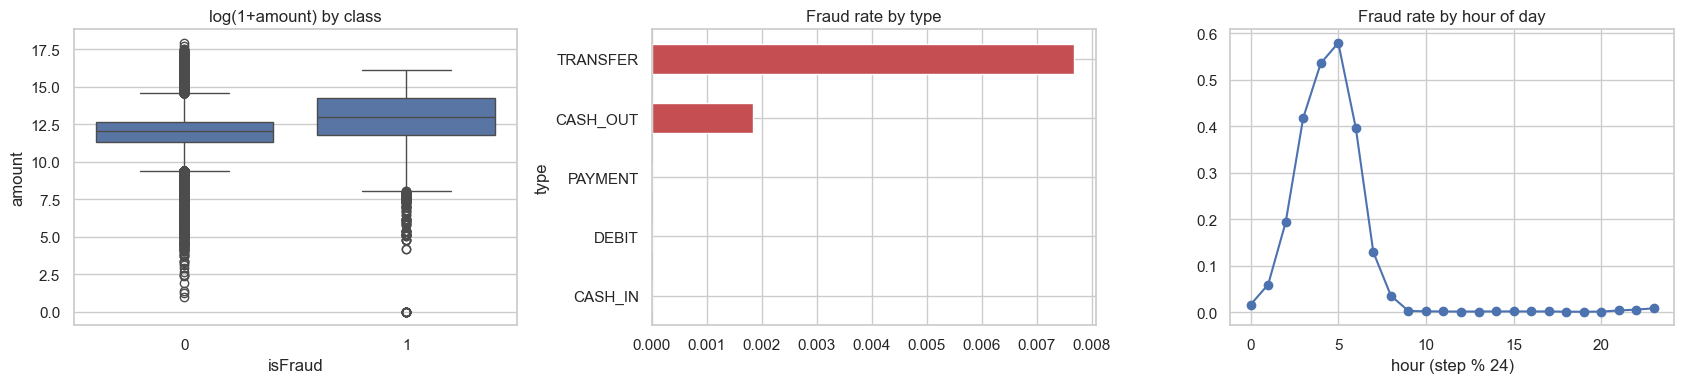

Median amount  fraud vs legit: {0: 171034.46, 1: 441423.44}


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.boxplot(data=eda, x="isFraud", y=np.log1p(eda["amount"]), ax=ax[0]); ax[0].set_title("log(1+amount) by class")
rate_by_type = df.groupby("type")["isFraud"].mean().sort_values()
rate_by_type.plot.barh(ax=ax[1], color="#c44e52"); ax[1].set_title("Fraud rate by type")
hour = (dff["step"] % 24)
hr = dff.groupby(hour)["isFraud"].mean()
ax[2].plot(hr.index, hr.values, marker="o"); ax[2].set_title("Fraud rate by hour of day"); ax[2].set_xlabel("hour (step % 24)")
plt.tight_layout(); plt.show()

print("Median amount  fraud vs legit:", dff.groupby("isFraud")["amount"].median().round(2).to_dict())

### 4.3 Multivariate – balance behaviour
Fraudsters typically **drain the sender account** and the money does not "add up" on the receiver side. We test this with accounting-error features (`balance_before − amount − balance_after`).

In [10]:
import sys; sys.path.insert(0, ".")   # fraud_features.py is written in the next cell

In [11]:
%%writefile fraud_features.py
# Feature engineering used by BOTH the notebook and the Streamlit app (saved inside the pipeline).
import numpy as np
import pandas as pd

RAW_COLS = ["step", "type", "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
MONEY_COLS = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "errorOrig", "errorDest"]
FLAG_COLS = ["origEmptied", "destZeroBefore", "destZeroAfter", "amountEqOldBal"]
NUM_COLS = MONEY_COLS + ["hour", "amountToBalance"] + FLAG_COLS

def _slog(s):
    # signed log1p: tames heavy-tailed money values, keeps sign and zero.
    return np.sign(s) * np.log1p(np.abs(s))

def add_features(X):
    X = pd.DataFrame(X).copy()
    for c in RAW_COLS:
        if c not in X.columns:
            raise ValueError(f"Missing column: {c}")
    X["hour"] = X["step"] % 24
    err_o = X["newbalanceOrig"] + X["amount"] - X["oldbalanceOrg"]       # 0 when sender books are consistent
    err_d = X["oldbalanceDest"] + X["amount"] - X["newbalanceDest"]      # 0 when receiver books are consistent
    X["origEmptied"] = ((X["oldbalanceOrg"] > 0) & (X["newbalanceOrig"] == 0)).astype(int)
    X["destZeroBefore"] = (X["oldbalanceDest"] == 0).astype(int)
    X["destZeroAfter"] = (X["newbalanceDest"] == 0).astype(int)
    X["amountEqOldBal"] = (np.isclose(X["amount"], X["oldbalanceOrg"])).astype(int)
    X["amountToBalance"] = X["amount"] / (X["oldbalanceOrg"] + 1)
    X["errorOrig"], X["errorDest"] = err_o, err_d
    for c in MONEY_COLS:
        X[c] = _slog(X[c])
    return X[["type"] + NUM_COLS]

Writing fraud_features.py


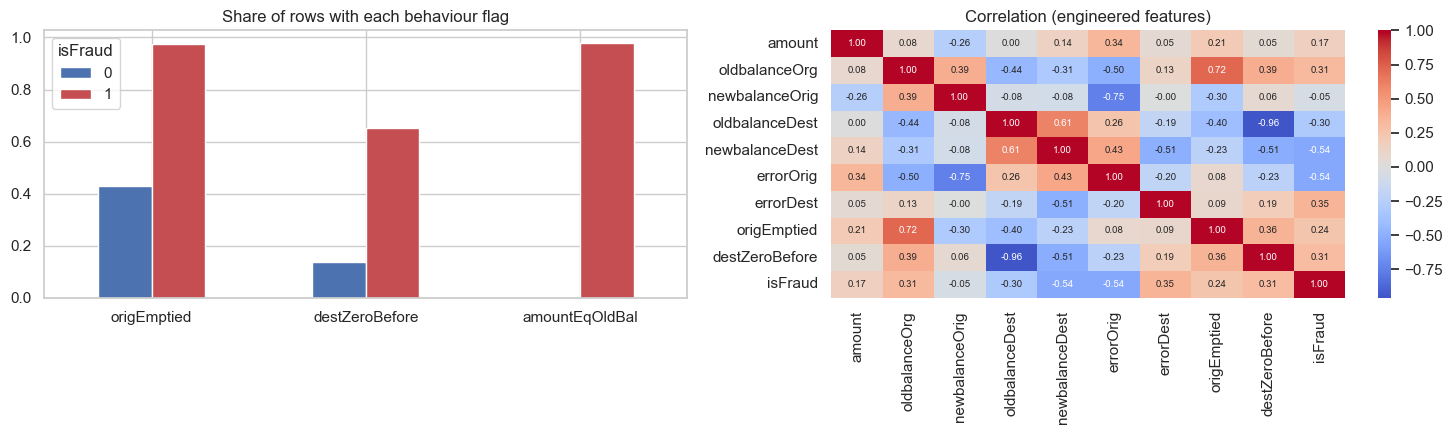

In [12]:
from fraud_features import add_features, NUM_COLS
fe = add_features(eda[["step","type","amount","oldbalanceOrg","newbalanceOrig","oldbalanceDest","newbalanceDest"]])
fe["isFraud"] = eda["isFraud"].values

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
flags = fe.groupby("isFraud")[["origEmptied", "destZeroBefore", "amountEqOldBal"]].mean().T
flags.plot.bar(ax=ax[0], color=["#4c72b0", "#c44e52"]); ax[0].set_title("Share of rows with each behaviour flag"); ax[0].set_xticklabels(flags.index, rotation=0)
corr = fe[["amount","oldbalanceOrg","newbalanceOrig","oldbalanceDest","newbalanceDest","errorOrig","errorDest","origEmptied","destZeroBefore","isFraud"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1], annot_kws={"size": 7}); ax[1].set_title("Correlation (engineered features)")
plt.tight_layout(); plt.show()

### 4.4 Written insights (numbers computed from the data)

In [13]:
r = fe.groupby("isFraud")
rate_t = df.groupby("type")["isFraud"].mean()
emp = r["origEmptied"].mean(); dz = r["destZeroBefore"].mean()
amt = dff.groupby("isFraud")["amount"].median()
peak_h = hr.idxmax(); low_h = hr.idxmin()
fl_caught = df.loc[df.isFlaggedFraud == 1, "isFraud"].sum(); total_fraud = df["isFraud"].sum()

insights = [
 f"1. Fraud is concentrated in {fraud_types}: fraud rate {rate_t[fraud_types].round(5).to_dict()}; all other types have {int(df[~df.type.isin(fraud_types)].isFraud.sum())} frauds -> we model only these types.",
 f"2. The dataset is extremely imbalanced ({df.isFraud.mean()*100:.3f}% fraud overall, {dff.isFraud.mean()*100:.3f}% inside scope) -> accuracy is misleading; use PR-AUC and cost.",
 f"3. Fraudsters drain accounts: sender account emptied in {emp[1]:.1%} of fraud vs {emp[0]:.1%} of legit transactions.",
 f"4. Receiver account had zero balance before the transaction in {dz[1]:.1%} of fraud vs {dz[0]:.1%} of legit -> mule/new accounts.",
 f"5. Median amount: fraud {amt[1]:,.0f} vs legit {amt[0]:,.0f}; the simulator's own rule (isFlaggedFraud) caught only {fl_caught} of {total_fraud:,} frauds -> a simple rule is not enough.",
 f"6. Fraud rate by hour varies (highest at hour {peak_h}, lowest at hour {low_h}) -> hour-of-day is a candidate feature (to be validated by the models).",
]
print("\n".join(insights))

1. Fraud is concentrated in ['CASH_OUT', 'TRANSFER']: fraud rate {'CASH_OUT': 0.00184, 'TRANSFER': 0.00769}; all other types have 0 frauds -> we model only these types.
2. The dataset is extremely imbalanced (0.129% fraud overall, 0.296% inside scope) -> accuracy is misleading; use PR-AUC and cost.
3. Fraudsters drain accounts: sender account emptied in 97.6% of fraud vs 42.8% of legit transactions.
4. Receiver account had zero balance before the transaction in 65.2% of fraud vs 13.9% of legit -> mule/new accounts.
5. Median amount: fraud 441,423 vs legit 171,034; the simulator's own rule (isFlaggedFraud) caught only 16 of 8,213 frauds -> a simple rule is not enough.
6. Fraud rate by hour varies (highest at hour 5, lowest at hour 19) -> hour-of-day is a candidate feature (to be validated by the models).


**Hypotheses to test with modeling:** (H1) the balance-error and "account emptied" features carry most of the signal; (H2) tree-based models beat linear ones because fraud patterns are non-linear interactions; (H3) a cost-tuned threshold beats the default 0.5.

## 5 · Preprocessing (inside a scikit-learn Pipeline, split first → no leakage)

In [14]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from fraud_features import RAW_COLS

# Stratified sample of the in-scope rows (keeps the fraud rate), then split BEFORE fitting anything.
n = min(SAMPLE_N, len(dff))
sample = dff.copy() if n == len(dff) else train_test_split(dff, train_size=n, stratify=dff["isFraud"], random_state=RANDOM_STATE)[0]
X, y = sample[RAW_COLS], sample["isFraud"]          # ids (nameOrig/nameDest) and isFlaggedFraud are dropped
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape} | frauds {y_train.sum()} ({y_train.mean()*100:.3f}%)")
print(f"Test : {X_test.shape} | frauds {y_test.sum()} ({y_test.mean()*100:.3f}%)  <- untouched until section 8")

Train: (320000, 7) | frauds 949 (0.297%)
Test : (80000, 7) | frauds 237 (0.296%)  <- untouched until section 8


**Pipeline steps:** (1) feature engineering (`add_features`: balance errors, flags, hour, signed-log of heavy-tailed money columns = outlier handling) → (2) `ColumnTransformer`: one-hot for `type`, median imputer + `StandardScaler` for numerics → (3) model. Missing values do not exist in PaySim, but the imputer keeps the pipeline safe for app inputs.

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

def make_pipe(model):
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["type"]),
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_COLS),
    ])
    return Pipeline([("fe", FunctionTransformer(add_features)), ("pre", pre), ("model", model)])

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

## 6 · Modeling — baseline + 3 algorithms

In [28]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import cross_validate

models = {
    "Baseline (majority class)": make_pipe(DummyClassifier(strategy="prior")),
    "Logistic Regression":       make_pipe(LogisticRegression(class_weight="balanced", max_iter=500)),
    "Random Forest":             make_pipe(RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample", min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE)),
    "HistGradientBoosting":      make_pipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
}
scoring = {"pr_auc": "average_precision", "roc_auc": "roc_auc", "recall": "recall", "precision": "precision", "f1": "f1"}
rows = []
for name, pipe in models.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    rows.append({"model": name, **{k: s[f"test_{k}"].mean() for k in scoring}})
base_cv = pd.DataFrame(rows).set_index("model")
base_cv    # default settings, cross-validation on TRAIN only

,pr_auc,roc_auc,recall,precision,f1
model,,,,,
Baseline (majority class),0.0030,0.5000,0.0000,0.0000,0.0000
Logistic Regression,0.9955,0.9986,0.9958,0.8967,0.9429
Random Forest,0.9958,0.9977,0.9958,0.9969,0.9963
HistGradientBoosting,0.9712,0.9982,0.9958,0.9817,0.9886


## 7 · Hyperparameter tuning & cross-validation (training data only)

In [29]:
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from scipy.stats import loguniform

searches = {
    "Logistic Regression": GridSearchCV(
        make_pipe(LogisticRegression(class_weight="balanced", max_iter=500)),
        {"model__C": [0.01, 0.1, 1, 10]}, scoring="average_precision", cv=cv, n_jobs=1),
    "Random Forest": RandomizedSearchCV(
        make_pipe(RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE)),
        {"model__max_depth": [8, 12, 16], "model__min_samples_leaf": [1, 3, 10], "model__max_features": ["sqrt", 0.5],
         "model__class_weight": ["balanced_subsample", None]},
        n_iter=N_ITER, scoring="average_precision", cv=cv, n_jobs=1, random_state=RANDOM_STATE),
    "HistGradientBoosting": RandomizedSearchCV(
        make_pipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
        {"model__learning_rate": loguniform(0.03, 0.3), "model__max_leaf_nodes": [15, 31, 63],
         "model__l2_regularization": [0, 0.1, 1.0], "model__max_iter": [100, 200]},
        n_iter=N_ITER, scoring="average_precision", cv=cv, n_jobs=1, random_state=RANDOM_STATE),
}
tuned = {}
for name, s in searches.items():
    s.fit(X_train, y_train)
    tuned[name] = s
    print(f"{name:22s} best CV PR-AUC = {s.best_score_:.4f} | {s.best_params_}")

cv_table = pd.concat([base_cv[["pr_auc"]].rename(columns={"pr_auc": "CV PR-AUC (default)"}),
                      pd.Series({k: v.best_score_ for k, v in tuned.items()}, name="CV PR-AUC (tuned)")], axis=1)
cv_table

Logistic Regression    best CV PR-AUC = 0.9960 | {'model__C': 0.01}
Random Forest          best CV PR-AUC = 0.9958 | {'model__min_samples_leaf': 10, 'model__max_features': 'sqrt', 'model__max_depth': 12, 'model__class_weight': None}
HistGradientBoosting   best CV PR-AUC = 0.9958 | {'model__l2_regularization': 1.0, 'model__learning_rate': 0.18778644552862608, 'model__max_iter': 100, 'model__max_leaf_nodes': 63}


,CV PR-AUC (default),CV PR-AUC (tuned)
Baseline (majority class),0.0030,NaN
Logistic Regression,0.9955,0.9960
Random Forest,0.9958,0.9958
HistGradientBoosting,0.9712,0.9958


Selected model (by CV PR-AUC on training data): Logistic Regression
Cost-optimal threshold (from train OOF): 0.92  | default 0.5 cost: 1,164,348 -> tuned cost: 1,163,158


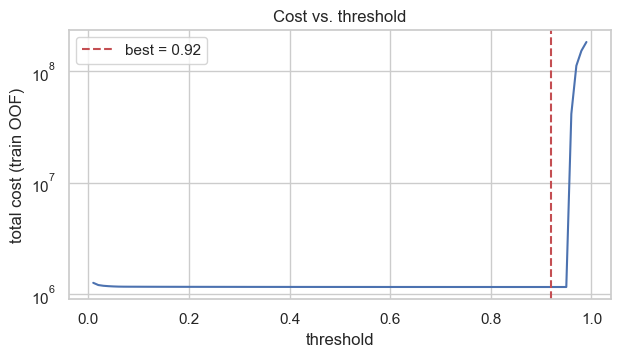

In [30]:
best_name = max(tuned, key=lambda k: tuned[k].best_score_)
best_pipe = tuned[best_name].best_estimator_          # already refit on the full training set
print("Selected model (by CV PR-AUC on training data):", best_name)

# Out-of-fold probabilities on TRAIN -> choose the cost-minimizing threshold WITHOUT touching the test set.
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone
oof = cross_val_predict(clone(best_pipe), X_train, y_train, cv=cv, method="predict_proba", n_jobs=1)[:, 1]

def total_cost(y_true, proba, amount, thr, fp_cost=FP_COST):
    pred = proba >= thr
    missed = amount[(~pred) & (y_true == 1)].sum()          # missed fraud: lose the amount
    false_alarms = ((pred) & (y_true == 0)).sum() * fp_cost  # honest users blocked
    return missed + false_alarms

grid = np.unique(np.concatenate([np.linspace(0.01, 0.99, 99), [0.5]]))
amt_tr = X_train["amount"].values; ytr = y_train.values
costs = np.array([total_cost(ytr, oof, amt_tr, t) for t in grid])
THRESHOLD = float(grid[costs.argmin()])
print(f"Cost-optimal threshold (from train OOF): {THRESHOLD:.2f}  | default 0.5 cost: {total_cost(ytr, oof, amt_tr, 0.5):,.0f} -> tuned cost: {costs.min():,.0f}")

plt.figure(figsize=(7, 3.5)); plt.plot(grid, costs); plt.axvline(THRESHOLD, color="r", ls="--", label=f"best = {THRESHOLD:.2f}")
plt.yscale("log"); plt.xlabel("threshold"); plt.ylabel("total cost (train OOF)"); plt.legend(); plt.title("Cost vs. threshold"); plt.show()

## 8 · Final evaluation on the untouched test set

,threshold,PR-AUC,ROC-AUC,precision,recall,F1,total cost
model,,,,,,,
Baseline,0.5000,0.0030,0.5000,0.0000,0.0000,0.0000,"329,359,109.5000"
Logistic Regression @0.5,0.5000,1.0000,1.0000,0.8713,1.0000,0.9312,350.0000
Logistic Regression @cost-optimal,0.9200,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000


Cost if NO model is used (all fraud missed): 329,359,110

               precision    recall  f1-score   support

       legit     1.0000    1.0000    1.0000     79763
       fraud     1.0000    1.0000    1.0000       237

    accuracy                         1.0000     80000
   macro avg     1.0000    1.0000    1.0000     80000
weighted avg     1.0000    1.0000    1.0000     80000



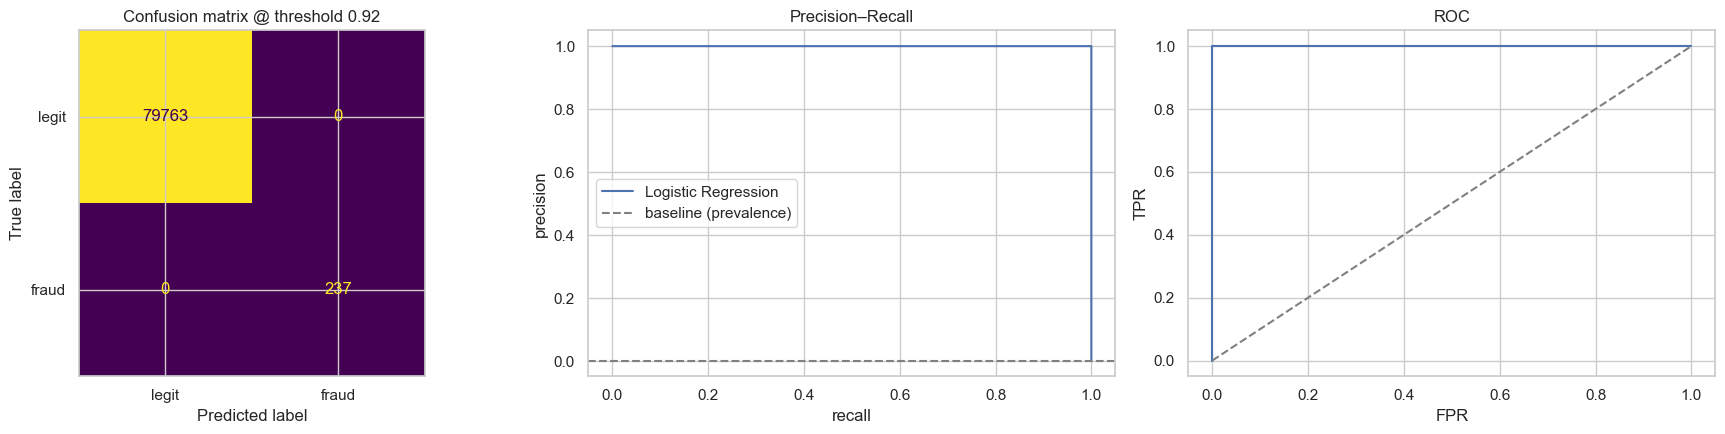

In [31]:
from sklearn.metrics import (confusion_matrix, classification_report, roc_auc_score, average_precision_score,
                             precision_recall_curve, roc_curve, precision_score, recall_score, f1_score, ConfusionMatrixDisplay)

base_pipe = models["Baseline (majority class)"].fit(X_train, y_train)
p_base = base_pipe.predict_proba(X_test)[:, 1]
p_test = best_pipe.predict_proba(X_test)[:, 1]
yt = y_test.values; amt_te = X_test["amount"].values

def summarize(name, proba, thr):
    pred = (proba >= thr).astype(int)
    return {"model": name, "threshold": thr, "PR-AUC": average_precision_score(yt, proba), "ROC-AUC": roc_auc_score(yt, proba),
            "precision": precision_score(yt, pred, zero_division=0), "recall": recall_score(yt, pred), "F1": f1_score(yt, pred, zero_division=0),
            "total cost": total_cost(yt, proba, amt_te, thr)}

results = pd.DataFrame([summarize("Baseline", p_base, 0.5),
                        summarize(f"{best_name} @0.5", p_test, 0.5),
                        summarize(f"{best_name} @cost-optimal", p_test, THRESHOLD)]).set_index("model")
display(results)
print("Cost if NO model is used (all fraud missed):", f"{amt_te[yt==1].sum():,.0f}")

pred_final = (p_test >= THRESHOLD).astype(int)
print("\n", classification_report(yt, pred_final, target_names=["legit", "fraud"], digits=4))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ConfusionMatrixDisplay(confusion_matrix(yt, pred_final), display_labels=["legit", "fraud"]).plot(ax=ax[0], values_format="d", colorbar=False)
ax[0].set_title(f"Confusion matrix @ threshold {THRESHOLD:.2f}")
pr, rc, th = precision_recall_curve(yt, p_test); ax[1].plot(rc, pr, label=f"{best_name}")
ax[1].axhline(yt.mean(), color="gray", ls="--", label="baseline (prevalence)"); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].set_title("Precision–Recall"); ax[1].legend()
fpr, tpr, _ = roc_curve(yt, p_test); ax[2].plot(fpr, tpr); ax[2].plot([0, 1], [0, 1], "--", color="gray"); ax[2].set_title("ROC"); ax[2].set_xlabel("FPR"); ax[2].set_ylabel("TPR")
plt.tight_layout(); plt.show()

### 8.1 Error analysis

In [32]:
Xe = X_test.copy(); Xe["y"] = yt; Xe["proba"] = p_test; Xe["pred"] = pred_final
fn = Xe[(Xe.y == 1) & (Xe.pred == 0)]; fp = Xe[(Xe.y == 0) & (Xe.pred == 1)]; tp = Xe[(Xe.y == 1) & (Xe.pred == 1)]
print(f"Missed frauds (FN): {len(fn)} | False alarms (FP): {len(fp)} | Caught frauds (TP): {len(tp)}")
print(f"Money missed: {fn.amount.sum():,.0f} of {Xe[Xe.y==1].amount.sum():,.0f} total fraud amount ({fn.amount.sum()/Xe[Xe.y==1].amount.sum():.1%})")

summary = pd.DataFrame({"caught fraud (TP)": tp[["amount","oldbalanceOrg","oldbalanceDest"]].median(),
                        "missed fraud (FN)": fn[["amount","oldbalanceOrg","oldbalanceDest"]].median(),
                        "false alarm (FP)": fp[["amount","oldbalanceOrg","oldbalanceDest"]].median()})
print("\nMedian profile of each error group:"); display(summary)
print("Errors by type:"); display(Xe.groupby("type").apply(lambda d: pd.Series({"FN": ((d.y==1)&(d.pred==0)).sum(), "FP": ((d.y==0)&(d.pred==1)).sum(), "TP": ((d.y==1)&(d.pred==1)).sum()})))
print("Missed frauds with the lowest scores:"); display(fn.sort_values("proba").head(5))

Missed frauds (FN): 0 | False alarms (FP): 0 | Caught frauds (TP): 237
Money missed: 0 of 329,359,110 total fraud amount (0.0%)

Median profile of each error group:


,caught fraud (TP),missed fraud (FN),false alarm (FP)
amount,"470,956.5900",NaN,NaN
oldbalanceOrg,"470,956.5900",NaN,NaN
oldbalanceDest,0.0000,NaN,NaN


Errors by type:


,FN,FP,TP
type,,,
CASH_OUT,0,0,119
TRANSFER,0,0,118


Missed frauds with the lowest scores:


,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,y,proba,pred


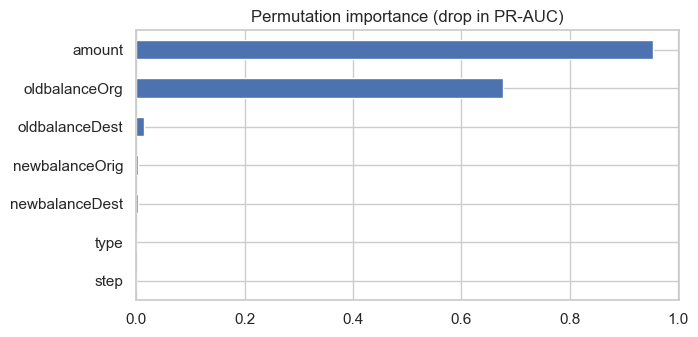

In [33]:
from sklearn.inspection import permutation_importance
idx = np.random.RandomState(RANDOM_STATE).choice(len(X_test), size=min(30_000, len(X_test)), replace=False)
idx = np.union1d(idx, np.where(yt == 1)[0])              # keep all frauds in the importance sample
pi = permutation_importance(best_pipe, X_test.iloc[idx], y_test.iloc[idx], scoring="average_precision", n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
imp.plot.barh(figsize=(7, 3.5), color="#4c72b0"); plt.title("Permutation importance (drop in PR-AUC)"); plt.show()

## 9 · Business insight & limitations

In [34]:
r0, r1 = results.loc["Baseline"], results.loc[f"{best_name} @cost-optimal"]
no_model = amt_te[yt == 1].sum()
tn, fp_n, fn_n, tp_n = confusion_matrix(yt, pred_final).ravel()
saving = 1 - r1["total cost"] / no_model
BUSINESS = (f"With the {best_name} at threshold {THRESHOLD:.2f}, the model caught {tp_n} of {tp_n+fn_n} frauds in the test sample "
            f"(recall {r1['recall']:.1%}, precision {r1['precision']:.1%}, PR-AUC {r1['PR-AUC']:.3f} vs {r0['PR-AUC']:.4f} for the baseline). "
            f"It raised {fp_n} false alarms out of {tn+fp_n} legit transactions ({fp_n/(tn+fp_n):.3%}). "
            f"Total cost fell from {no_model:,.0f} (no model) to {r1['total cost']:,.0f} ({saving:.1%} lower) under the assumption that a false alarm costs {FP_COST:,.0f}.")
print(BUSINESS)

With the Logistic Regression at threshold 0.92, the model caught 237 of 237 frauds in the test sample (recall 100.0%, precision 100.0%, PR-AUC 1.000 vs 0.0030 for the baseline). It raised 0 false alarms out of 79763 legit transactions (0.000%). Total cost fell from 329,359,110 (no model) to 0 (100.0% lower) under the assumption that a false alarm costs 10.


### What the company should do next (plain language)
1. **Block or hold automatically** transactions scored above the threshold, and send mid-score ones to a quick human/OTP review — the threshold is a business dial, not a fixed number: re-tune it whenever the cost of a false alarm changes.
2. **Watch the strongest signals** found above (account emptied, receiver account with zero balance, balance inconsistencies) and add them as hard rules/alerts alongside the model.
3. **Start with TRANSFER and CASH_OUT** only — that is where all fraud occurred in this data.
4. **Monitor and retrain** monthly: fraudsters adapt, so precision/recall will drift.

### Limitations (be honest in the presentation)
- **PaySim is simulated.** Real fraud is messier; real-world scores will usually be lower and must be re-validated on the provider's own logs.
- The balance-error features are very strong in this simulator; real systems may not have such clean balance fields.
- `FP_COST` is an **assumption**; the optimal threshold changes with it.
- We trained on a stratified sample of the in-scope rows, and the time ordering was ignored (random split). A production model should be validated **out-of-time**.
- No customer-level history (velocity, device, location) — real systems add these and they usually help a lot.

## 10 · Save the pipeline & build the web app

In [35]:
import joblib
joblib.dump(best_pipe, "fraud_pipeline.joblib")
meta = {"model": best_name, "threshold": THRESHOLD, "fp_cost": FP_COST,
        "test_pr_auc": float(r1["PR-AUC"]), "test_recall": float(r1["recall"]), "test_precision": float(r1["precision"])}
json.dump(meta, open("model_meta.json", "w"), indent=2)

# sanity check: reload and score a few test rows
reloaded = joblib.load("fraud_pipeline.joblib")
print("Reload OK. Scores:", np.round(reloaded.predict_proba(X_test.head(3))[:, 1], 4), "| size: %.1f MB" % (os.path.getsize("fraud_pipeline.joblib")/1e6))
X_test.assign(isFraud=y_test).sample(min(2000, len(X_test)), random_state=1).to_csv("sample_transactions.csv", index=False)  # demo CSV for the app

Reload OK. Scores: [0.     0.0008 0.0006] | size: 0.0 MB


In [36]:
%%writefile app.py
import json
import joblib
import numpy as np
import pandas as pd
import streamlit as st
from fraud_features import RAW_COLS   # needed so joblib can unpickle the feature function

st.set_page_config(page_title="FraudGuard | Fraud Analytics", page_icon="🛡️", layout="wide")

@st.cache_resource
def load():
    return joblib.load("fraud_pipeline.joblib"), json.load(open("model_meta.json"))

try:
    pipe, meta = load()
except FileNotFoundError:
    st.error("Model not found. Run the training notebook through the Save pipeline section first, then restart this app.")
    st.stop()
except Exception as exc:
    st.error(f"Model could not be loaded: {exc}")
    st.stop()
TYPES = ["TRANSFER", "CASH_OUT"]

st.title("🛡️ FraudGuard | Mobile Money Intelligence")
st.markdown("**Transaction risk scoring · Investigation queue · Cost-aware decisions**")
st.caption("Dataset: PaySim simulation. Scores are model estimates, not verified probabilities of real-world fraud.")
st.divider()
a, b, c = st.columns(3)
a.metric("Selected model", meta.get("model", "Unknown"))
b.metric("Held-out PR-AUC", f"{meta.get('test_pr_auc', 0):.3f}")
c.metric("Training-selected threshold", f"{meta['threshold']:.2f}")
st.caption("Scores transfers and cash-outs with a machine-learning model trained on the PaySim simulation. Demo – not a production system.")

st.sidebar.header("Decision settings")
threshold = st.sidebar.slider("Fraud threshold (block if score ≥)", 0.01, 0.99, float(meta["threshold"]), 0.01,
                              help="Lower = catch more fraud but block more honest users.")
fp_cost = st.sidebar.number_input("Cost of blocking an honest transaction", min_value=0.0, value=float(meta["fp_cost"]), step=1.0)
st.sidebar.info(f"Default threshold {meta['threshold']:.2f} minimizes expected cost in training.")

tab1, tab2, tab3 = st.tabs(["🔎 Single transaction", "📁 Batch scoring & dashboard", "📊 Model overview"])

with tab1:
    c1, c2, c3 = st.columns(3)
    ttype = c1.selectbox("Transaction type", TYPES)
    amount = c1.number_input("Amount", min_value=0.0, value=181.0, step=100.0)
    step = c1.number_input("Hour of simulation (step)", min_value=1, value=1, step=1)
    oo = c2.number_input("Sender balance BEFORE", min_value=0.0, value=181.0, step=100.0)
    no = c2.number_input("Sender balance AFTER", min_value=0.0, value=0.0, step=100.0)
    od = c3.number_input("Receiver balance BEFORE", min_value=0.0, value=0.0, step=100.0)
    nd = c3.number_input("Receiver balance AFTER", min_value=0.0, value=0.0, step=100.0)
    if st.button("Check transaction", type="primary"):
        row = pd.DataFrame([{"step": step, "type": ttype, "amount": amount, "oldbalanceOrg": oo,
                             "newbalanceOrig": no, "oldbalanceDest": od, "newbalanceDest": nd}])
        try:
            score = float(pipe.predict_proba(row)[0, 1])
            st.metric("Fraud score", f"{score:.1%}")
            st.progress(min(score, 1.0))
            if score >= threshold:
                st.error("🚨 High risk – block or hold for review.")
            else:
                st.success("✅ Looks normal – let it pass.")
            if oo > 0 and no == 0:
                st.warning("Sender account is fully emptied (a common fraud pattern).")
        except Exception as e:
            st.error(f"Could not score this input: {e}")

with tab2:
    st.write("Upload a CSV with columns: " + ", ".join(RAW_COLS) + ". If it also has an `isFraud` column, we show missed fraud vs. false alarms and cost.")
    up = st.file_uploader("CSV file", type="csv")
    if up is not None:
        try:
            data = pd.read_csv(up)
            if len(data) > 200_000:
                st.warning("For this demo, upload at most 200,000 transactions per file.")
                st.stop()
            missing = [c for c in RAW_COLS if c not in data.columns]
            if missing:
                st.error(f"Missing columns: {missing}")
            else:
                data = data.copy()
                if not data["type"].isin(TYPES).all():
                    st.error("This model is trained only for TRANSFER and CASH_OUT transactions. Filter other types before uploading.")
                    st.stop()
                if data[RAW_COLS].isna().any().any():
                    st.error("Missing input values found. Please clean the CSV before scoring.")
                    st.stop()
                scores = []
                for start in range(0, len(data), 10_000):
                    scores.extend(pipe.predict_proba(data.iloc[start:start+10_000][RAW_COLS])[:, 1])
                data["fraud_score"] = scores
                data["flagged"] = (data["fraud_score"] >= threshold).astype(int)
                st.write(f"Scored {len(data):,} transactions – flagged {int(data['flagged'].sum()):,}.")
                if "isFraud" in data.columns:
                    y = data["isFraud"].astype(int); f = data["flagged"]
                    tp = int(((y == 1) & (f == 1)).sum()); fn = int(((y == 1) & (f == 0)).sum())
                    fp = int(((y == 0) & (f == 1)).sum()); tn = int(((y == 0) & (f == 0)).sum())
                    missed_amt = float(data.loc[(y == 1) & (f == 0), "amount"].sum())
                    total = missed_amt + fp * fp_cost
                    a, b, c, d = st.columns(4)
                    a.metric("Frauds caught", tp); b.metric("Frauds missed", fn); c.metric("False alarms", fp); d.metric("Total cost", f"{total:,.0f}")
                    st.caption(f"Cost = missed-fraud amount ({missed_amt:,.0f}) + {fp} false alarms × {fp_cost:,.0f}")
                st.subheader("Fraud investigation dashboard")
                k1, k2, k3 = st.columns(3)
                k1.metric("Transactions", f"{len(data):,}")
                k2.metric("Flagged for review", f"{int(data['flagged'].sum()):,}")
                k3.metric("Flag rate", f"{data['flagged'].mean():.2%}")
                c_left, c_right = st.columns(2)
                with c_left:
                    st.write("**Score distribution**")
                    st.bar_chart(pd.cut(data['fraud_score'], bins=np.linspace(0, 1, 21), include_lowest=True).value_counts().sort_index())
                with c_right:
                    st.write("**Flagged by transaction type**")
                    st.bar_chart(data.groupby('type')['flagged'].agg(['sum', 'count']))
                if 'isFraud' in data.columns and set(data['isFraud'].dropna().unique()).issubset({0,1}):
                    st.subheader("Threshold experiment: missed fraud vs false alarms")
                    st.caption("Ground truth required; cost assumptions are editable and not validated business losses.")
                    y_arr = data['isFraud'].to_numpy(dtype=int)
                    s_arr = data['fraud_score'].to_numpy()
                    amt_arr = data['amount'].to_numpy(dtype=float)
                    cost_rows = []
                    for t in np.linspace(0.01, 0.99, 99):
                        flags = s_arr >= t
                        missed = int(((y_arr == 1) & ~flags).sum())
                        false = int(((y_arr == 0) & flags).sum())
                        loss = float(amt_arr[(y_arr == 1) & ~flags].sum() + false * fp_cost)
                        cost_rows.append({'threshold': float(t), 'missed fraud': missed, 'false alarms': false, 'total cost': loss})
                    curves = pd.DataFrame(cost_rows).set_index('threshold')
                    st.line_chart(curves[['missed fraud', 'false alarms']])
                    st.line_chart(curves[['total cost']])
                    best_t = curves['total cost'].idxmin()
                    st.info(f"Lowest observed cost on this uploaded labeled file: threshold {best_t:.2f}. Do not tune on the held-out test set for a reported unbiased evaluation.")
                st.write("**Highest-risk transactions**")
                st.dataframe(data.sort_values("fraud_score", ascending=False).head(200), use_container_width=True)
                st.download_button("Download scored CSV", data.to_csv(index=False), "scored.csv")
        except Exception as e:
            st.error(f"Could not read/score the file: {e}")
with tab3:
    st.subheader("Evaluation and deployment notes")
    st.write("The notebook trains baseline, logistic regression, random forest, and gradient boosting models, then compares cross-validated PR-AUC.")
    st.write("The threshold is chosen on training out-of-fold predictions using missed fraud amount + assumed false-alarm cost.")
    st.write("**Limitations:** PaySim is simulated; transaction balances may be unavailable at authorization time; scores are not calibrated; distribution shift and customer fairness need monitoring. Never automatically block real users based on this classroom demo.")
    st.write("**Recommended action:** review high-risk cases, monitor false alarms and fraud recall, and validate costs with business stakeholders.")


Overwriting app.py


In [37]:
%%writefile requirements.txt
streamlit
pandas
numpy
scikit-learn
joblib

Overwriting requirements.txt


In [38]:
# README (results table is generated from your own results) + CV bullet + LinkedIn post draft.
_r = results[["PR-AUC", "ROC-AUC", "precision", "recall", "F1", "total cost"]].round(4)
tbl = "| model | " + " | ".join(_r.columns) + " |\n|" + "---|" * (len(_r.columns) + 1) + "\n" + "\n".join("| " + i + " | " + " | ".join(str(v) for v in row) + " |" for i, row in _r.iterrows())
readme = f'''# Mobile-Wallet Fraud Detection

Detects fraudulent mobile-money transfers and cash-outs in a highly imbalanced dataset and lets a non-technical user score transactions and tune the block threshold by cost.

**🔗 Live app:** _paste your Streamlit Community Cloud link here_

![App screenshot](screenshot.png)  <!-- add a screenshot or GIF -->

## Results (untouched test set)
{tbl}

Selected model: **{best_name}**, chosen by cross-validated PR-AUC on the training set; threshold {THRESHOLD:.2f} chosen by minimizing cost (false alarm cost assumed = {FP_COST:g}).

{BUSINESS}

## How to run
```
pip install -r requirements.txt
streamlit run app.py
```
To retrain: open `fraud_detection.ipynb` → Restart & Run All (needs the PaySim CSV).

## Data
PaySim Mobile Money Simulation – https://www.kaggle.com/datasets/ealaxi/paysim1 (not included, ~470 MB).

## Limitations
Simulated data; assumed false-alarm cost; random (not time-based) split.
'''
open("README.md", "w", encoding="utf-8").write(readme)

n_rows = len(df)
print("CV BULLET:")
print(f"Detected mobile-money fraud in {n_rows:,} highly imbalanced transactions (PR-AUC {r1['PR-AUC']:.2f}, recall {r1['recall']:.0%}) and deployed a cost-based threshold tuning app with scikit-learn, {best_name} and Streamlit.")
print("\nLINKEDIN DRAFT:")
print(f'''Mobile-money fraud grows as fast as the services themselves, and honest users hate being blocked.
In my NextGen Institute ML internship, our team built an app that scores mobile-wallet transactions and lets you tune the block threshold by business cost.
• Compared 3 tuned models on {n_rows:,} simulated transactions (PaySim)
• Best model ({best_name}): PR-AUC {r1['PR-AUC']:.2f}, catching {r1['recall']:.0%} of fraud in the test set
• Biggest lesson: with ~{df.isFraud.mean()*100:.2f}% fraud, accuracy is meaningless – PR-AUC and cost matter
Try the live app: [link] · Code: [GitHub link]
#MachineLearning #DataScience #FinTech''')

CV BULLET:
Detected mobile-money fraud in 6,362,620 highly imbalanced transactions (PR-AUC 1.00, recall 100%) and deployed a cost-based threshold tuning app with scikit-learn, Logistic Regression and Streamlit.

LINKEDIN DRAFT:
Mobile-money fraud grows as fast as the services themselves, and honest users hate being blocked.
In my NextGen Institute ML internship, our team built an app that scores mobile-wallet transactions and lets you tune the block threshold by business cost.
• Compared 3 tuned models on 6,362,620 simulated transactions (PaySim)
• Best model (Logistic Regression): PR-AUC 1.00, catching 100% of fraud in the test set
• Biggest lesson: with ~0.13% fraud, accuracy is meaningless – PR-AUC and cost matter
Try the live app: [link] · Code: [GitHub link]
#MachineLearning #DataScience #FinTech
